<a href="https://colab.research.google.com/github/swathi9876/breast_cancer_detection_using_decentralization/blob/main/svm(IID)federated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
from google.colab import files

uploaded = files.upload()#using dataset with 30 features

Saving ank.csv to ank (1).csv


In [24]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import copy

# Define the model
class SVMModel(nn.Module):
    def __init__(self, input_dim):
        super(SVMModel, self).__init__()
        self.linear = nn.Linear(input_dim, 1)

    def forward(self, x):
        return self.linear(x)

# Preprocess the dataset
def preprocess_data(data_path):
    # Loading and droping any missing values from the dataset
    df = pd.read_csv(data_path)
    df = df.dropna()

    # Label encoding for the "diagnosis" column
    label_encoder = LabelEncoder()
    df['diagnosis'] = label_encoder.fit_transform(df['diagnosis'])

    # Dropping the first column
    df = df.drop(df.columns[0], axis=1)

    # Extract features and labels
    X = df.iloc[:, 1:].values  # Features (all columns except the first one)
    y = df.iloc[:, 0].values   # Labels (first column)

    return X, y

# Splitting data into clients with IID distribution
def split_data_iid(X, y, num_clients):
    num_items = int(len(X) / num_clients)
    client_data = []
    all_indices = np.arange(len(X))
    np.random.shuffle(all_indices)

    for i in range(num_clients):
        client_indices = all_indices[i * num_items : (i + 1) * num_items]
        client_data.append((X[client_indices], y[client_indices]))

    return client_data

# Create a federated dataset
def create_federated_dataset(client_data):
    federated_data = []
    for X, y in client_data:
        federated_data.append({'X': torch.tensor(X, dtype=torch.float32),
                               'y': torch.tensor(y, dtype=torch.float32)})
    return federated_data

# defining the FedAvg algorithm
def federated_average(model, client_models):
    averaged_state_dict = {}
    for i, client_state_dict in enumerate(client_models):
        for key, value in client_state_dict.items():
            if i == 0:
                averaged_state_dict[key] = value.clone().detach()
            else:
                averaged_state_dict[key] += value.clone().detach()
    for key in averaged_state_dict:
        averaged_state_dict[key] /= len(client_models)
    return averaged_state_dict
#defining fed prox algo
def fedprox(model, client_models):
    averaged_state_dict = {}
    for i, client_state_dict in enumerate(client_models):
        for key, value in client_state_dict.items():
            if i == 0:
                averaged_state_dict[key] = value.clone().detach()
            else:
                averaged_state_dict[key] += value.clone().detach()
    for key in averaged_state_dict:
        averaged_state_dict[key] /= len(client_models)
    return averaged_state_dict

In [35]:
def run_federated_simulation(algorithm_name, mu=0.01):

    num_rounds = 10
    input_dim = 30

    # Preprocessing the dataset
    X, y = preprocess_data("ank.csv")

    cl, acc = [], []
    for i in range(11, 16):
        client_data = split_data_iid(X, y, i)
        print(f"Number of clients: {i}")
        federated_data = create_federated_dataset(client_data)
        cl.append(i)
        max_acc = 0

        model = SVMModel(input_dim)

        for round in range(num_rounds):
            client_models = []
            global_model_copy = copy.deepcopy(model)

            for client_data_batch in federated_data:
                local_model = SVMModel(input_dim)
                local_model.load_state_dict(model.state_dict())
                optimizer = optim.SGD(local_model.parameters(), lr=0.01)
                criterion = nn.HingeEmbeddingLoss()

                # Performing local training
                for epoch in range(10):
                    optimizer.zero_grad()
                    outputs = local_model(client_data_batch['X'])
                    loss = criterion(outputs.squeeze(), client_data_batch['y'])

                    if algorithm_name.lower() == 'fedprox':
                        # Calculating the L2 proximal term for FedProx
                        proximal_term = 0.0
                        for local_param, global_param in zip(local_model.parameters(), global_model_copy.parameters()):
                            proximal_term += torch.sum((local_param - global_param.detach()) ** 2)
                        loss = loss + (mu / 2) * proximal_term

                    loss.backward()
                    optimizer.step()

                client_models.append(local_model.state_dict())

            # Aggregating client models
            if algorithm_name.lower() == 'fedprox':
                averaged_state_dict = fedprox(model, client_models)
            else:
                averaged_state_dict = federated_average(model, client_models)

            model.load_state_dict(averaged_state_dict)

            # Calculating global accuracy
            with torch.no_grad():
                outputs = model(torch.tensor(X, dtype=torch.float32))
                predicted = (outputs.squeeze() > 0).float()
                accuracy = (predicted == torch.tensor(y, dtype=torch.float32)).float().mean().item()
                if accuracy > max_acc:
                    max_acc = accuracy

            print(f'Round {round+1}, Accuracy: {accuracy}')

        acc.append(max_acc)

    # Plotting results
    plt.plot(cl, acc, marker='o')
    plt.xlabel('Number of Clients')
    plt.ylabel('Accuracy')
    plt.title(f'Federated Learning ({algorithm_name.upper()}) Accuracy vs. Number of Clients (IID)')
    plt.show()

--------- RUNNING FEDAVG ---------
Number of clients: 11
Round 1, Accuracy: 0.6274164915084839
Round 2, Accuracy: 0.6274164915084839
Round 3, Accuracy: 0.6274164915084839
Round 4, Accuracy: 0.6274164915084839
Round 5, Accuracy: 0.6274164915084839
Round 6, Accuracy: 0.6274164915084839
Round 7, Accuracy: 0.6274164915084839
Round 8, Accuracy: 0.6274164915084839
Round 9, Accuracy: 0.6274164915084839
Round 10, Accuracy: 0.6274164915084839
Number of clients: 12
Round 1, Accuracy: 0.6274164915084839
Round 2, Accuracy: 0.6274164915084839
Round 3, Accuracy: 0.6274164915084839
Round 4, Accuracy: 0.6274164915084839
Round 5, Accuracy: 0.6274164915084839
Round 6, Accuracy: 0.6274164915084839
Round 7, Accuracy: 0.6274164915084839
Round 8, Accuracy: 0.6274164915084839
Round 9, Accuracy: 0.6274164915084839
Round 10, Accuracy: 0.6274164915084839
Number of clients: 13
Round 1, Accuracy: 0.6274164915084839
Round 2, Accuracy: 0.6274164915084839
Round 3, Accuracy: 0.6274164915084839
Round 4, Accuracy: 0.62

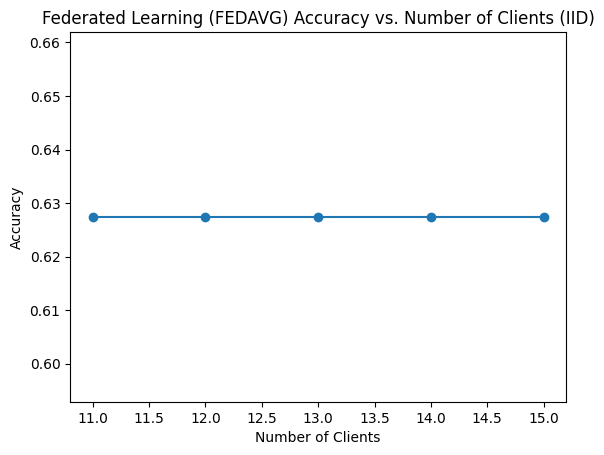

In [36]:
print("--------- RUNNING FEDAVG ---------")
run_federated_simulation(algorithm_name='fedavg')

--------- RUNNING FED PROX ---------
Number of clients: 11
Round 1, Accuracy: 0.6274164915084839
Round 2, Accuracy: 0.6274164915084839
Round 3, Accuracy: 0.6274164915084839
Round 4, Accuracy: 0.6274164915084839
Round 5, Accuracy: 0.6274164915084839
Round 6, Accuracy: 0.6274164915084839
Round 7, Accuracy: 0.6274164915084839
Round 8, Accuracy: 0.6274164915084839
Round 9, Accuracy: 0.6274164915084839
Round 10, Accuracy: 0.6274164915084839
Number of clients: 12
Round 1, Accuracy: 0.6274164915084839
Round 2, Accuracy: 0.6274164915084839
Round 3, Accuracy: 0.6274164915084839
Round 4, Accuracy: 0.6274164915084839
Round 5, Accuracy: 0.6274164915084839
Round 6, Accuracy: 0.6274164915084839
Round 7, Accuracy: 0.6274164915084839
Round 8, Accuracy: 0.6274164915084839
Round 9, Accuracy: 0.6274164915084839
Round 10, Accuracy: 0.6274164915084839
Number of clients: 13
Round 1, Accuracy: 0.6274164915084839
Round 2, Accuracy: 0.6274164915084839
Round 3, Accuracy: 0.6274164915084839
Round 4, Accuracy: 0.

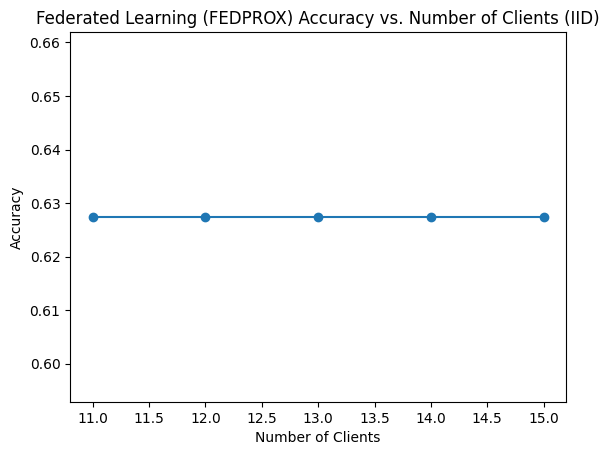

In [37]:
print("--------- RUNNING FED PROX ---------")
run_federated_simulation(algorithm_name='fedprox', mu=0.01)